In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
def sigmoid(z):
    """
    Convert linear outputs into probabilities between 0 and 1.
    """
    return 1 / (1 + np.exp(-z))

In [5]:
z_values = np.array([-5, -2, 0, 2, 5])

probabilities = sigmoid(z_values)

for z, probability in zip(z_values, probabilities):
    print(f"z = {z:>2} | Probability = {probability:.4f}")

z = -5 | Probability = 0.0067
z = -2 | Probability = 0.1192
z =  0 | Probability = 0.5000
z =  2 | Probability = 0.8808
z =  5 | Probability = 0.9933


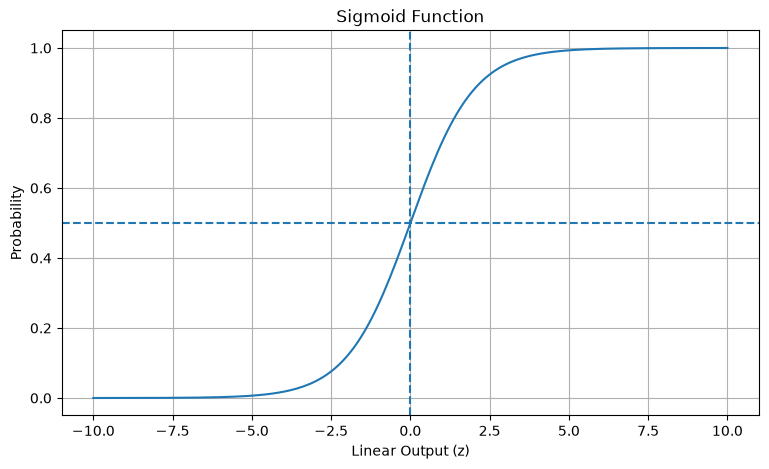

In [6]:
z = np.linspace(-10, 10, 200)

probabilities = sigmoid(z)

plt.figure(figsize=(9, 5))

plt.plot(z, probabilities)

plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")

plt.xlabel("Linear Output (z)")
plt.ylabel("Probability")
plt.title("Sigmoid Function")

plt.grid(True)
plt.show()

In [7]:
def logistic_predict_probability(X, weight, bias):
    z = np.dot(X, weight) + bias
    return sigmoid(z)


def logistic_predict_class(X, weight, bias, threshold=0.5):
    probabilities = logistic_predict_probability(
        X, weight, bias
    )

    return (probabilities >= threshold).astype(int)

In [8]:
X = np.array([5])

weight = 0.8
bias = -2

probability = logistic_predict_probability(
    X, weight, bias
)

prediction = logistic_predict_class(
    X, weight, bias
)

print("Spam probability:", probability)
print("Predicted class:", prediction)

Spam probability: [0.88079708]
Predicted class: [1]


In [9]:
def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-15

    # Prevent log(0)
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    # Calculate binary cross-entropy
    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [10]:
y_true = np.array([1])

prediction_A = np.array([0.95])
prediction_B = np.array([0.15])

loss_A = binary_cross_entropy(y_true, prediction_A)
loss_B = binary_cross_entropy(y_true, prediction_B)

print("Model A Loss:", loss_A)
print("Model B Loss:", loss_B)

Model A Loss: 0.05129329438755058
Model B Loss: 1.8971199848858813


In [11]:
def compute_gradients(X, y, weight, bias):
    n_samples = X.shape[0]

    # Step 1: Calculate predictions
    probabilities = logistic_predict_probability(
        X, weight, bias
    )

    # Step 2: Calculate prediction errors
    errors = probabilities - y

    # Step 3: Calculate gradients
    dw = (X.T @ errors) / n_samples
    db = np.mean(errors)

    return dw, db

In [12]:
def train_logistic_regression(
    X,
    y,
    learning_rate=0.01,
    epochs=1000
):
    n_samples, n_features = X.shape

    # Initialize parameters
    weight = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # 1. Forward propagation: calculate probabilities
        probabilities = logistic_predict_probability(
            X, weight, bias
        )

        # 2. Calculate loss
        loss = binary_cross_entropy(y, probabilities)
        loss_history.append(loss)

        # 3. Calculate errors
        errors = probabilities - y

        # 4. Calculate gradients
        dw = (X.T @ errors) / n_samples
        db = np.mean(errors)

        # 5. Update parameters
        weight -= learning_rate * dw
        bias -= learning_rate * db

    return weight, bias, loss_history

In [13]:
X = np.array([
    [1],
    [2],
    [3],
    [4],
    [5],
    [6],
    [7],
    [8]
], dtype=float)

y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

In [14]:
weight, bias, loss_history = train_logistic_regression(
    X,
    y,
    learning_rate=0.1,
    epochs=2000
)

print("Weight:", weight)
print("Bias:", bias)
print("Final Loss:", loss_history[-1])

Weight: [1.74427359]
Bias: -7.632308076009153
Final Loss: 0.11038877708847289


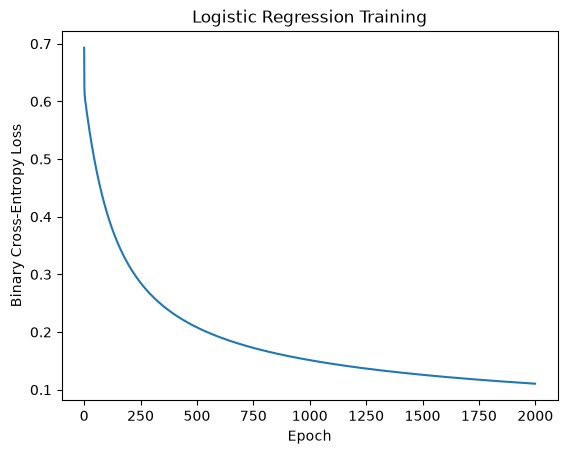

In [15]:
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Logistic Regression Training")
plt.show()

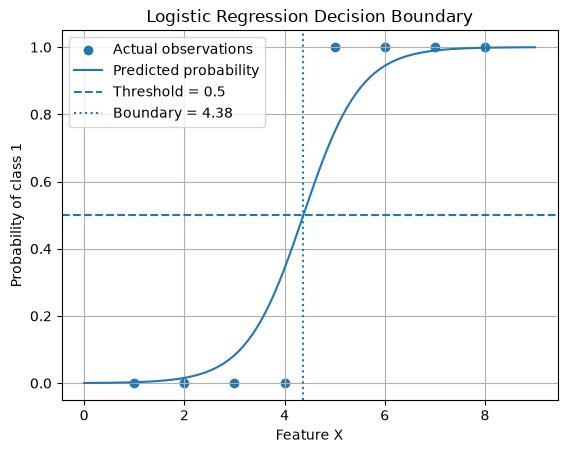

In [16]:
# Generate values for a smooth probability curve
X_plot = np.linspace(0, 9, 200).reshape(-1, 1)

# Predict probabilities
probabilities = logistic_predict_probability(
    X_plot, weight, bias
)

# Plot actual observations
plt.scatter(X, y, label="Actual observations")

# Plot learned probability curve
plt.plot(
    X_plot,
    probabilities,
    label="Predicted probability"
)

# Decision threshold
plt.axhline(
    y=0.5,
    linestyle="--",
    label="Threshold = 0.5"
)

# Decision boundary
decision_boundary = -bias / weight[0]

plt.axvline(
    x=decision_boundary,
    linestyle=":",
    label=f"Boundary = {decision_boundary:.2f}"
)

plt.xlabel("Feature X")
plt.ylabel("Probability of class 1")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.grid()
plt.show()

In [17]:
def logistic_predict_class(X, weight, bias, threshold=0.5):
    probabilities = logistic_predict_probability(X, weight, bias)
    return (probabilities >= threshold).astype(int)

In [18]:
predictions = logistic_predict_class(X, weight, bias)

print("Actual:", y)
print("Predicted:", predictions)

Actual: [0 0 0 0 1 1 1 1]
Predicted: [0 0 0 0 1 1 1 1]


In [19]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Actual and predicted labels
y_true = np.array([1] * 100 + [0] * 100)

y_pred = np.array(
    [1] * 80 + [0] * 20 +
    [1] * 10 + [0] * 90
)

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# Evaluation metrics
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Confusion Matrix:
[[90 10]
 [20 80]]
Accuracy: 0.85
Precision: 0.8888888888888888
Recall: 0.8
F1 Score: 0.8421052631578947

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       100
           1       0.89      0.80      0.84       100

    accuracy                           0.85       200
   macro avg       0.85      0.85      0.85       200
weighted avg       0.85      0.85      0.85       200

